# Water Rights Restored to the Gila River

The impacts of irrigation on vegetation health in the Gila River Valley


## Set up
To get started on this notebook, you’ll need to restore any variables from previous notebooks to your workspace. To save time and memory, make sure to specify which variables you want to load.

In [2]:
%store -r ndvi_ds gila_river_gdf


You will also need to import any libraries you are using in this
notebook, since they won’t carry over from the previous notebook:

In [3]:
### import libraries
import matplotlib.pyplot as plt
import rioxarray as rxr
import hvplot.pandas
import hvplot.xarray
import holoviews as hv
import panel as pn

pn.extension(comms='vscode', inline=True)
hv.extension('bokeh')

# Use the boundary name expected by the later template notebooks.
your_gdf = gila_river_gdf


## Step 4: Plot NDVI

To plot the change in NDVI spatially, complete the following:

1. Calculate the mean NDVI before the water rights case (2001-2007):
    - Take the temporal mean (over the **date**, not spatially)  
    - Specify that you want the mean NDVI value 

2. Repeat this process to calculate the mean NDVI for the years after the water rights case (2013-2022)

3. Calculate the difference in the mean NDVI across the two time periods.
    - Subtract the 2013-2022 time period from the 2001-2007 time period   

4. Plot the result
    - Use a **diverging** color map like `cmap = plt.cm.PiYG`. There are different types of color maps for different types of data. In this case, we want decreases to be a different color from increases, so we should use a diverging color map. Check out available colormaps in the [matplotlib documentation](https://matplotlib.org/stable/tutorials/colors/colormaps.html)

c:\Users\gekek\Documents\03-vegetation-fall-template\notebooks\ndvi-map.html

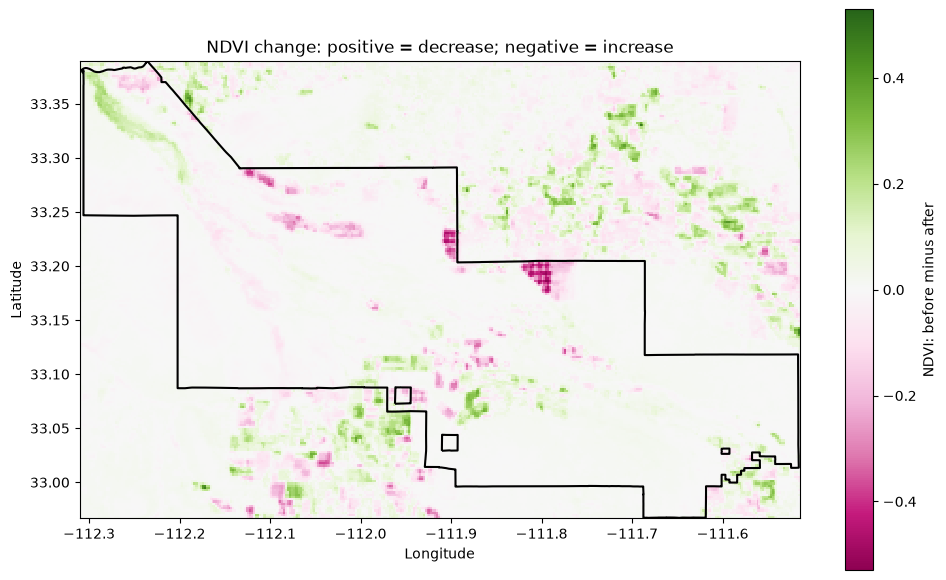

In [4]:
### calculate the mean NDVI before the event
ndvi_pre = ndvi_ds.NDVI.sel(date=slice('2001', '2007')).mean('date')

### calculate the mean NDVI after the event
ndvi_post = ndvi_ds.NDVI.sel(date=slice('2013', '2022')).mean('date')

### follow the assignment: subtract post-event NDVI from pre-event NDVI
# Positive values mean lower NDVI in the later period; negative values mean higher NDVI.
ndvi_diff = ndvi_pre - ndvi_post
ndvi_diff.name = 'NDVI difference (before minus after)'

### use Web Mercator coordinates to match the satellite basemap
ndvi_map_data = ndvi_diff.rio.reproject('EPSG:3857')
boundary_map_data = your_gdf.to_crs(epsg=3857)

### keep the color scale centered on zero
color_limit = float(abs(ndvi_diff).max())
if color_limit == 0:
    color_limit = 0.01

### plot the difference and overlay the community boundary
ndvi_map = (
    ndvi_map_data.hvplot(
        x='x', y='y',
        geo=False,
        tiles='EsriImagery',
        cmap=plt.cm.PiYG,
        clim=(-color_limit, color_limit),
        colorbar=True,
        clabel='NDVI: before minus after',
        title='NDVI change: positive = decrease; negative = increase',
        frame_width=650
    )
    * boundary_map_data.hvplot(
        geo=False,
        fill_color=None,
        line_color='black',
        line_width=2
    )
)

# Save the interactive map so it can be opened without notebook widgets.
from IPython.display import FileLink, display
hv.save(ndvi_map, 'ndvi-map.html', resources='inline')
display(FileLink('ndvi-map.html', result_html_prefix='Interactive map: '))

# Display a static preview directly in the notebook (without satellite tiles).
fig, ax = plt.subplots(figsize=(10, 6))
ndvi_diff.plot(
    ax=ax, x='x', y='y', cmap=plt.cm.PiYG,
    vmin=-color_limit, vmax=color_limit,
    cbar_kwargs={'label': 'NDVI: before minus after'}
)
your_gdf.to_crs(ndvi_diff.rio.crs).boundary.plot(ax=ax, color='black')
ax.set_title('NDVI change: positive = decrease; negative = increase')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.tight_layout()
plt.show()


## Wrap up Step 4

Don’t forget to store your variables so you can use them in other notebooks! Replace `var1` and `var2` with the variable you want to save, separated by spaces.

In [5]:
%store ndvi_pre ndvi_post ndvi_diff your_gdf


Stored 'ndvi_pre' (DataArray)
Stored 'ndvi_post' (DataArray)
Stored 'ndvi_diff' (DataArray)
Stored 'your_gdf' (GeoDataFrame)


Finally, be sure to `Restart` and `Run all` to make sure your notebook
works all the way through!